# 3.1 — Classification Fundamentals

## 3.1.1 — Classification vs. Regression

## 1. What Is the Difference?

Both regression and classification are **supervised machine learning** tasks. In both cases, a model learns from labeled training data containing features (`X`) and a target (`y`).

The main difference is the type of target we want to predict.

### Regression

Regression predicts a **numerical quantity**.

**Example:** Predicting a house's price based on its size, location, and number of bedrooms.

- Input features (`X`): House size, location, number of bedrooms
- Target (`y`): House price
- Example prediction: `8500000`

Common regression algorithms include `LinearRegression`, `Ridge`, `Lasso`, and `ElasticNet`.

Common evaluation metrics include MAE, MSE, RMSE, and R².

### Classification

Classification predicts a **category or class**.

**Example:** Predicting whether an email is spam or not spam.

- Input features (`X`): Email content, sender information, other relevant features
- Target (`y`): Spam or Not Spam
- Example prediction: `Spam`

Common classification algorithms include `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier`, and `RandomForestClassifier`.

Common evaluation metrics include accuracy, precision, recall, F1-score, and ROC-AUC.

## 2. Why Not Use Linear Regression for Classification?

Suppose we encode a student's result as:

- `0` = Fail
- `1` = Pass

Linear Regression could produce predictions such as `-0.3`, `0.65`, or `1.4`.

These outputs are not restricted to valid class labels. We could apply a threshold, such as predicting Pass when the output is at least `0.5`, but Linear Regression is not designed to model class probabilities appropriately.

Classification algorithms, such as Logistic Regression, are designed for categorical targets.

A classification model may calculate probabilities internally. For example, it might estimate a 90% probability that an email is spam and then predict the class `Spam`.

## 3. Comparison

| Aspect | Regression | Classification |
|---|---|---|
| Target | Numerical quantity | Category or class |
| Example | House price prediction | Spam detection |
| Output | A numerical value | A predicted class |
| Typical algorithm | `LinearRegression` | `LogisticRegression` |
| Common metrics | MAE, RMSE, R² | Accuracy, Precision, Recall, F1 |

## 4. Examples

| Problem | Type |
|---|---|
| Predicting a household's monthly electricity bill | Regression |
| Predicting whether a transaction is fraudulent | Classification |
| Predicting tomorrow's temperature | Regression |
| Identifying an image as a cat, dog, or bird | Classification |
| Predicting a student's final numerical score | Regression |
| Predicting whether a student passes or fails | Classification |

## 5. Key Takeaways

- **Regression predicts a numerical quantity.**
- **Classification predicts a category or class.**
- Both are supervised learning tasks that learn from labeled data.
- Classification models can use numerical scores or probabilities internally, even though their final predictions are classes.
- The type of target helps determine which algorithms and evaluation metrics are appropriate.


## 3.1.2 — Binary vs. Multiclass Classification

## 1. Binary Classification

Predicts **one of exactly two classes**.

Examples: Spam/Not Spam, Fraudulent/Legitimate, Pass/Fail.

## 2. Multiclass Classification

Predicts **one class from three or more possible classes**.

Examples: Cat/Dog/Bird, or classifying news as Sports/Politics/Business.

## 3. Simple Scikit-Learn Example

`LogisticRegression` supports both binary and multiclass classification.

```python
from sklearn.linear_model import LogisticRegression

# Binary classification
X_binary = [[1], [2], [3], [4]]
y_binary = [0, 0, 1, 1]

binary_model = LogisticRegression()
binary_model.fit(X_binary, y_binary)

print(binary_model.predict([[2.5]]))

# Multiclass classification
X_multi = [[1], [2], [3], [4], [5], [6]]
y_multi = [0, 0, 1, 1, 2, 2]

multi_model = LogisticRegression()
multi_model.fit(X_multi, y_multi)

print(multi_model.predict([[5.5]]))
```

Here:
- Binary classification has two classes: `0` and `1`.
- Multiclass classification has three classes: `0`, `1`, and `2`.
- `fit()` trains the model, while `predict()` predicts a class for new input.

These tiny datasets are only for demonstrating the API, not for building reliable predictive models.

## Key Takeaways

- **Binary:** Exactly two classes.
- **Multiclass:** Three or more classes, with one predicted class per example.
- The same algorithm can often handle both.


## 3.1.3 — Features, Labels, and Class Predictions

## 1. Features (`X`) and Labels (`y`)

- **Features (`X`):** Input information used to make predictions.
- **Labels (`y`):** The correct target classes the model learns to predict.

Example: Predicting whether a student passes an exam.

| Hours Studied (`X`) | Pass? (`y`) |
|---:|---|
| 1 | Fail |
| 2 | Fail |
| 4 | Pass |
| 6 | Pass |

In Scikit-Learn, `X` is usually a 2D array or DataFrame, while `y` is usually a 1D array or Series.

## 2. Training vs. Prediction

- `model.fit(X, y)`: Learns patterns from features and their known labels.
- `model.predict(X_new)`: Predicts classes for new inputs.

**True label:** The correct class in the dataset.

**Predicted class:** The class predicted by the model. Predictions can be incorrect, so we evaluate models using metrics such as accuracy, precision, recall, and F1-score.

## Key Takeaways

- `X` contains features (inputs).
- `y` contains labels (target classes).
- `fit()` trains the model.
- `predict()` predicts classes for new examples.


In [38]:
from sklearn.linear_model import LogisticRegression

# Features: hours studied
X = [[1], [2], [3], [4], [5], [6]]

# Labels: 0 = Fail, 1 = Pass
y = [0, 0, 0 , 1, 1, 1]

model = LogisticRegression()
model.fit(X, y)

prediction = model.predict([[3.5]])

print(prediction)

[1]


## 3.1.4 — The Classification Workflow

## 1. Typical Workflow

A classification task generally follows these steps:

1. **Load the dataset:** Obtain features (`X`) and labels (`y`).
2. **Split the data:** Separate training data from test data.
3. **Preprocess the data:** Handle missing values, encode categorical features, and scale features when necessary.
4. **Choose a classifier:** For example, Logistic Regression or a Decision Tree.
5. **Train the model:** Use `fit(X_train, y_train)`.
6. **Make predictions:** Use `predict(X_test)`.
7. **Evaluate performance:** Compare predictions with the true labels using appropriate metrics.

## 2. Why Split the Dataset?

Evaluating a model on the same examples used for training may give an overly optimistic picture of its performance on unseen data.

- **Training set:** Used to train the model.
- **Test set:** Used to evaluate the trained model on unseen examples.

An 80/20 split is a common starting point, with 80% for training and 20% for testing.

For classification, `train_test_split` can use `stratify=y` to preserve class proportions across the splits.

## 3. Important Practices

- Split the data before fitting the model.
- Train using `X_train` and `y_train`.
- Evaluate predictions against `y_test`.
- Fit preprocessing steps, such as a scaler, on training data only, then apply them to test data. Pipelines help prevent data leakage.
- Choose evaluation metrics appropriate to the problem.

## Key Takeaway

The goal is not merely to train a classifier, but to evaluate how well it generalizes to unseen data.



# 3.2 — Logistic Regression

## 3.2.1 — Introduction to Logistic Regression

## 1. Why Logistic Regression?

Linear Regression predicts numerical values, but classification requires predicting categories.

For example:
- `0` = Fail
- `1` = Pass

Linear Regression can produce values below `0` or above `1`, which are not valid probabilities.

**Logistic Regression estimates the probability that an example belongs to a class.**

## 2. How It Works

First, Logistic Regression calculates a linear score:

$$
z = w_1x_1 + w_2x_2 + \cdots + b
$$

It then applies the **sigmoid function** to convert that score into a probability:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

The output is always between `0` and `1`.

Examples:

| Linear Score (\(z\)) | Probability (\(\sigma(z)\)) |
|---:|---:|
| -2 | 0.119 |
| 0 | 0.500 |
| 2 | 0.881 |

## 3. From Probability to Class

A common default decision threshold is `0.5`.

- Probability ≥ `0.5`: Predict class `1`.
- Probability < `0.5`: Predict class `0`.

For example, a predicted probability of `0.85` results in class `1` using the default threshold.

The threshold can be adjusted depending on the problem.

## 4. Why Is It Called Logistic Regression?

Logistic Regression models the **log-odds** of a class as a linear function of the input features, then uses the sigmoid function to estimate its probability.

Despite its name, it is a **classification algorithm**.

## Key Takeaways

- Linear Regression predicts numerical quantities.
- Logistic Regression estimates class probabilities.
- The sigmoid function converts a linear score into a probability between `0` and `1`.
- A decision threshold converts the probability into a class prediction.
- `0.5` is a common default threshold, not a universal rule.


## 3.2.2 Understanding `predict_proba()`

In classification, `predict()` returns the predicted class, while `predict_proba()` returns the estimated probability of each class.

- `predict()` tells us **which class the model predicts**.
- `predict_proba()` tells us **how probable each class is according to the model**.

For binary classification, the probabilities correspond to the classes in `model.classes_` order and sum to approximately 1.

For example, `[0.15, 0.85]` means the model estimates a 15% probability for class `0` and an 85% probability for class `1`.

By default, binary logistic regression predicts class `1` when its estimated probability reaches the default decision threshold of 0.5.

**Remember:** Predicted probabilities are estimates, not guarantees.

In [39]:
from sklearn.linear_model import LogisticRegression

# Features: hours studied
X = [[1], [2], [3], [4], [5], [6]]

# Labels: 0 = Fail, 1 = Pass
y = [0, 0, 0 , 1, 1, 1]

model = LogisticRegression()
model.fit(X, y)

prediction = model.predict([[3.5]])
prediction_prob = model.predict_proba([[3.5]])

print(prediction)
print(prediction_prob)


[1]
[[0.4999676 0.5000324]]


## 3.2.3 Decision Thresholds

A **decision threshold** determines how much probability a model needs to predict class `1` instead of class `0`.

For binary classification, the decision rule is:

$$
\hat{y} =
\begin{cases}
1, & \text{if } P(y=1 \mid x) \geq t \\
0, & \text{if } P(y=1 \mid x) < t
\end{cases}
$$

Where:
- \(\hat{y}\) = predicted class.
- \(P(y=1 \mid x)\) = estimated probability of class `1`.
- \(t\) = decision threshold, usually \(0.5\) by default.

**Example:** If the probability of class `1` is \(0.65\):
- Threshold \(0.3\) → predict class `1`.
- Threshold \(0.5\) → predict class `1`.
- Threshold \(0.7\) → predict class `0`.

### Why does the threshold matter?

- **Lower threshold:** Typically produces more positive predictions and may catch more actual positive cases, but can increase false positives.
- **Higher threshold:** Typically produces fewer positive predictions and may reduce false positives, but can miss more actual positive cases.

### Practical experiment

We used `make_classification()` to generate a synthetic dataset with two classes, `0` and `1`. These classes have no specific real-world meaning in our experiment.

We trained one Logistic Regression model and changed its decision threshold to observe how its predictions changed.

To inspect individual predictions, compare:

- **Probability:** The model's estimated probability of class `1`.
- **Predicted class:** The model's decision at the selected threshold.
- **Actual class:** The correct label provided by the dataset.

If the predicted class differs from the actual class, the model made a mistake on that sample.

**Key takeaway:** Changing the threshold changes how probabilities become class predictions; it does not retrain the model or change its predicted probabilities.

In [40]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification


X, y = make_classification(
    n_samples = 200,
    n_features = 4,
    n_informative = 3,
    n_redundant = 1,
    random_state = 42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

model = LogisticRegression()
model.fit(X_train, y_train)


#probabilities of class 1
probabilities = model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities >= threshold).astype(int)

    print(f"Threshold: {threshold}")
    print("Positive predictions:", np.sum(predictions == 1))
    print("First 10 predictions:", predictions[:10])
    print()

for i in range(10):
    print(
        f"Sample {i}: "
        f"Probability of class 1 = {probabilities[i]:.3f}, "
        f"Predicted class = {predictions[i]}, "
        f"Actual class = {y_test[i]}"
    )

Threshold: 0.3
Positive predictions: 17
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Threshold: 0.5
Positive predictions: 16
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Threshold: 0.7
Positive predictions: 16
First 10 predictions: [0 1 1 1 0 1 1 0 1 0]

Sample 0: Probability of class 1 = 0.056, Predicted class = 0, Actual class = 0
Sample 1: Probability of class 1 = 0.999, Predicted class = 1, Actual class = 1
Sample 2: Probability of class 1 = 0.913, Predicted class = 1, Actual class = 1
Sample 3: Probability of class 1 = 0.992, Predicted class = 1, Actual class = 1
Sample 4: Probability of class 1 = 0.005, Predicted class = 0, Actual class = 0
Sample 5: Probability of class 1 = 0.999, Predicted class = 1, Actual class = 1
Sample 6: Probability of class 1 = 0.993, Predicted class = 1, Actual class = 1
Sample 7: Probability of class 1 = 0.106, Predicted class = 0, Actual class = 0
Sample 8: Probability of class 1 = 0.969, Predicted class = 1, Actual class = 1
Sample 9: Probability of 

## 3.2.4 Training a Logistic Regression Model

Logistic Regression learns patterns from labeled training data to predict the class of new samples.

**1. Load the dataset**

We use Scikit-Learn's built-in Breast Cancer Wisconsin dataset.

- `X` contains the input features (30 numerical measurements per tumor).
- `y` contains the target labels: `0` = malignant, `1` = benign.

**2. Split the dataset**

We divide the data into training and testing sets.

- `X_train`, `y_train`: Used to train the model.
- `X_test`, `y_test`: Reserved for evaluating the trained model.
- `test_size=0.2`: Uses 20% of the samples for testing.
- `stratify=y`: Preserves approximately the same class proportions in both sets.

**3. Train the model**

The `LogisticRegression()` constructor creates the model, and `model.fit(X_train, y_train)` learns its parameters from the training data.

**4. Make predictions**

- `model.predict(X_train)` generates predictions for the training samples.
- `model.predict(X_test)` generates predictions for unseen test samples.

The predictions are stored in `train_pred` and `test_pred`, respectively.

**5. Evaluate accuracy**

`accuracy_score()` compares predicted labels against the actual labels.

$$
\text{Accuracy} =
\frac{\text{Number of correct predictions}}
{\text{Total number of predictions}}
$$

**Results:**

- Training accuracy: approximately **95.60%**
- Testing accuracy: approximately **96.49%**

The test accuracy being slightly higher than the training accuracy is possible and does not automatically indicate a problem.

**Key takeaway:** The model learns from `X_train` and `y_train`, predicts using `X_test`, and is evaluated by comparing `test_pred` against `y_test`. The test set acts like an answer key that is kept separate during training.

In [41]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_breast_cancer


data = load_breast_cancer()

X = data.data
y = data.target

print(f"Features : {data.feature_names}")
print(f"Classes : {data.target_names}")
print()

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

#Evaluate the model
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print(f"Training Accuracy : {accuracy_score(y_train, train_pred)}")
print(f"Testing Accuracy : {accuracy_score(y_test, test_pred)}")

Features : ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Classes : ['malignant' 'benign']

Training Accuracy : 0.9560439560439561
Testing Accuracy : 0.9649122807017544


## 3.2.5 Feature Scaling for Logistic Regression

Feature scaling transforms numerical features to comparable scales, helping Logistic Regression optimize its parameters more efficiently.

**Standardization** uses the following formula:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:
- \(x\) = original feature value.
- \(\mu\) = feature mean.
- \(\sigma\) = feature standard deviation.
- \(z\) = standardized value.

### Using `StandardScaler`

`StandardScaler()` creates a scaler object that can learn scaling parameters and transform numerical features.

- `scaler.fit(X_train)`: Learns the mean and standard deviation of each training feature.
- `scaler.transform(X_train)`: Scales the features using the learned parameters.
- `scaler.fit_transform(X_train)`: Performs both operations and returns the scaled data.

The original dataset remains unchanged; the transformed values are stored in a separate variable.

### Training Logistic Regression with Scaled Features

The workflow is:

1. Create the scaler using `StandardScaler()`.
2. Use `fit_transform()` on the training features to learn scaling parameters and scale the data.
3. Use `transform()` on the test features with the same learned parameters.
4. Train Logistic Regression using `model.fit(X_train_scaled, y_train)`.

**Why not use `fit_transform()` on the model?**

`fit_transform()` is a method of transformers such as `StandardScaler`, not `LogisticRegression`.

- `scaler.fit_transform(...)` learns scaling parameters and transforms features.
- `model.fit(...)` learns the Logistic Regression coefficients and intercept from the features and their target labels.

Using the training set's scaling parameters on the test set prevents data leakage during preprocessing.

**Key takeaway:** The scaler transforms the features; Logistic Regression learns from those transformed features. Feature scaling can improve optimization and make regularization more consistent across features, although it does not guarantee higher accuracy.

In [42]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Model without scaling
model_unscaled = LogisticRegression(max_iter=10000)
model_unscaled.fit(X_train, y_train)

pred_unscaled = model_unscaled.predict(X_test)


#Scaling the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

#Model with scaling
model_scaled = LogisticRegression(max_iter=10000)
model_scaled.fit(X_train_scaled, y_train)

pred_scaled = model_scaled.predict(X_test_scaled)

print("Accuracy without scaling:",
      accuracy_score(y_test, pred_unscaled))

print("Accuracy with scaling:",
      accuracy_score(y_test, pred_scaled))

Accuracy without scaling: 0.9649122807017544
Accuracy with scaling: 0.9824561403508771


## 3.2.6 Multiclass Logistic Regression

### What is Multiclass Classification?

Multiclass classification predicts one class from **three or more mutually exclusive classes**.

For example, the Iris dataset contains three flower classes:

- Setosa (0)
- Versicolor (1)
- Virginica (2)

Unlike binary classification, which distinguishes between two classes, multiclass classification chooses among multiple possible classes.

### How Does Logistic Regression Handle Multiple Classes?

Scikit-learn's `LogisticRegression` supports multiclass classification. It learns to distinguish between the available classes and can estimate the probability of each class.

We can use:

- `fit()` to train the model.
- `predict()` to predict the class.
- `predict_proba()` to obtain the probability of each class.
- `classes_` to identify the class order used by the model.

### Understanding Predicted Probabilities

Suppose `model.classes_` returns:

```python
[0, 1, 2]
```

And `predict_proba()` returns:

```python
[[0.02, 0.95, 0.03]]
```

The probabilities correspond to classes 0, 1, and 2, respectively.

| Class | Probability |
|---|---:|
| Setosa (0) | 0.02 |
| Versicolor (1) | 0.95 |
| Virginica (2) | 0.03 |

The model predicts **Versicolor (class 1)** because it has the highest probability.

The probabilities across the classes sum to approximately 1.

### Important Points

- Multiclass classification is supported by both Scikit-learn and deep learning frameworks such as TensorFlow.
- Traditional ML models, including Logistic Regression, KNN, Decision Trees, Random Forests, and SVMs, can be implemented using Scikit-learn.
- In multiclass classification, `predict()` generally selects the class with the highest predicted probability.
- Unlike binary classification, there is no single universal 0.5 threshold applied to all classes.
- Feature scaling is often helpful for Logistic Regression, so fit the scaler on the training data and use it to transform both training and test data.

In [43]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np

# Load dataset
data = load_iris()
X = data.data
y = data.target

print("Features:", data.feature_names)
print("Classes:", data.target_names)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#Scaler Features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

model = LogisticRegression(max_iter=10000)
model.fit(X_train_scaled, y_train)


#Evaluate
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))

print()

probabilities = model.predict_proba(X_test_scaled)

np.set_printoptions(suppress=True, precision=7)

print(probabilities[:5])
print(y_pred[:5])
print(f"Class Order : {model.classes_}")

print()

#How predict() is picking the class

print(f"Predicted Class : {y_pred[:5]}")
print(f"Predicted probabilities : {probabilities[:5]}")

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Accuracy: 0.9666666666666667

[[0.9783172 0.0216824 0.0000005]
 [0.0023823 0.3144947 0.683123 ]
 [0.1007828 0.886713  0.0125041]
 [0.0592765 0.9265408 0.0141826]
 [0.9894312 0.0105686 0.0000002]]
[0 2 1 1 0]
Class Order : [0 1 2]

Predicted Class : [0 2 1 1 0]
Predicted probabilities : [[0.9783172 0.0216824 0.0000005]
 [0.0023823 0.3144947 0.683123 ]
 [0.1007828 0.886713  0.0125041]
 [0.0592765 0.9265408 0.0141826]
 [0.9894312 0.0105686 0.0000002]]


# 3.3 Classification Evaluation

Classification evaluation helps us measure how well a classification model performs and understand the types of mistakes it makes.

A model's performance should not be judged by accuracy alone. Depending on the problem, false positives and false negatives may have very different consequences.

## 3.3.1 — Why Accuracy Alone Can Be Misleading

### What Is Accuracy?

Accuracy measures the proportion of predictions that the model classifies correctly.

$$
\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Number of Predictions}}
$$

For example, if a model correctly predicts 90 out of 100 samples, its accuracy is 90%.

### The Problem with Imbalanced Datasets

An imbalanced dataset contains significantly different numbers of samples belonging to different classes.

Consider a disease-detection dataset containing 1,000 people:

- 990 people do not have the disease (class 0).
- 10 people have the disease (class 1).

Suppose a model predicts class 0 for every person.

- It correctly classifies all 990 people without the disease.
- It incorrectly classifies all 10 people with the disease.

Its accuracy is:

$$
\text{Accuracy} = \frac{990}{1000} = 0.99 = 99\%
$$

Despite achieving 99% accuracy, the model fails to detect any person with the disease.

### Key Takeaway

**High accuracy does not always mean a good classifier.** When a dataset is imbalanced, a model can achieve high accuracy by predicting only the majority class.

Therefore, we need additional evaluation metrics to understand how well a model identifies each class and what types of mistakes it makes.

We will learn about the confusion matrix, precision, recall, F1-score, and other classification evaluation metrics in the following sections.

In [44]:
from sklearn.metrics import accuracy_score
import numpy as np

# Actual labels: 990 people without disease, 10 with disease
y_true = np.array([0] * 990 + [1] * 10)

# Model predicts no disease for everyone
y_pred = np.zeros(1000, dtype=int)

print(f"Accuracy : {accuracy_score(y_true, y_pred)}")


Accuracy : 0.99


## 3.3.2 — Confusion Matrix

A **confusion matrix** evaluates a classification model by comparing its actual labels with its predicted labels. It shows how many predictions were correct and incorrect for each class.

### 1. Creating a Confusion Matrix

We can use Scikit-learn's `confusion_matrix()` function.

```python
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)
print(cm)
```

For our disease-detection experiment, the output is:

```text
[[990   0]
 [ 10   0]]
```

Here:
- `0` = No disease
- `1` = Has disease

### 2. How to Read a Confusion Matrix

In Scikit-learn, **rows represent actual classes, and columns represent predicted classes**.

| Actual / Predicted | No disease (0) | Disease (1) |
|---|---:|---:|
| No disease (0) | 990 | 0 |
| Disease (1) | 10 | 0 |

Each cell tells us how many samples belong to a particular combination of actual and predicted labels.

- **990:** People without the disease correctly predicted as having no disease.
- **0:** People without the disease incorrectly predicted as having the disease.
- **10:** People with the disease incorrectly predicted as having no disease.
- **0:** People with the disease correctly identified as having the disease.

The matrix reveals that the model misses all 10 disease cases, despite achieving 99% accuracy.

### 3. The Four Outcomes of Binary Classification

The four cells have specific names:

| Term | Meaning | Our result |
|---|---|---:|
| True Negative (TN) | Actual 0, predicted 0 | 990 |
| False Positive (FP) | Actual 0, predicted 1 | 0 |
| False Negative (FN) | Actual 1, predicted 0 | 10 |
| True Positive (TP) | Actual 1, predicted 1 | 0 |

Remember:

- **True** means the prediction is correct.
- **False** means the prediction is incorrect.
- **Positive** refers to class 1.
- **Negative** refers to class 0.

A **False Negative** means the model misses a real positive case. A **False Positive** means the model incorrectly predicts a positive case.

### 4. Calculating Accuracy from the Confusion Matrix

The diagonal cells contain the correct predictions: TN and TP.

$$
\text{Accuracy} = \frac{TN+TP}{TN+FP+FN+TP}
$$

For our experiment:

$$
\text{Accuracy} = \frac{990+0}{990+0+10+0} = 0.99 = 99\%
$$

Although accuracy is 99%, the model fails to detect every person with the disease. This demonstrates why accuracy alone can be misleading.

### 5. Visualizing the Confusion Matrix

Scikit-learn can display the matrix as a plot.

```python
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease"]
).plot()

plt.show()
```

The visualization makes it easier to compare correct and incorrect predictions.

### 6. Confusion Matrices for Multiclass Classification

Confusion matrices also work for classification problems with three or more classes.

For example, our Iris dataset contains three classes:
- Setosa (0)
- Versicolor (1)
- Virginica (2)

Its confusion matrix has three rows and three columns. Each row represents an actual flower class, and each column represents a predicted class.

```python
from sklearn.metrics import confusion_matrix

cm_iris = confusion_matrix(y_test, predictions)
print(cm_iris)
```

The diagonal cells show correctly classified flowers, while off-diagonal cells show which classes the model confused with one another.

### Key Takeaways

- A confusion matrix compares actual labels with predicted labels.
- Rows represent actual classes; columns represent predicted classes.
- Diagonal cells represent correct predictions; off-diagonal cells represent mistakes.
- TN, FP, FN, and TP describe the four outcomes of binary classification.
- Confusion matrices work for both binary and multiclass classification.
- Accuracy can be calculated from the confusion matrix, but additional metrics are needed to understand different types of errors.

In [45]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Actual labels: 990 people without disease, 10 with disease
y_true = np.array([0] * 990 + [1] * 10)

# Model predicts no disease for everyone
y_pred = np.zeros(1000, dtype=int)

cm = confusion_matrix(y_true, y_pred)
print(cm)

[[990   0]
 [ 10   0]]


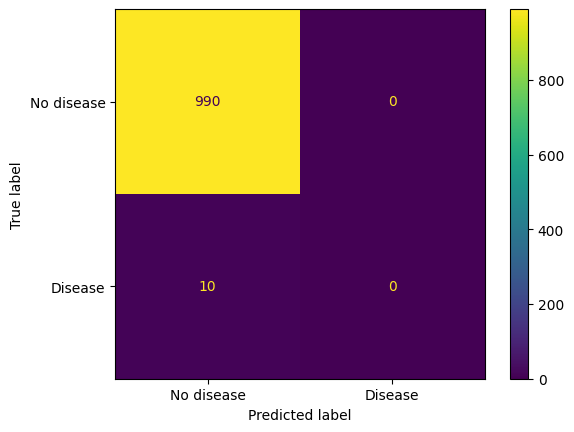

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No disease", "Disease"]
).plot();

### Multiclass Confusion Matrix

(150, 4)
(30, 4)
(30,)

[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Accuracy : 96.67%

Feature Names : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target Names : ['setosa' 'versicolor' 'virginica']



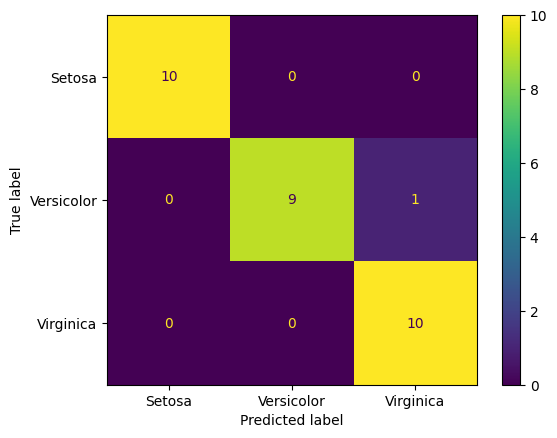

In [47]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

Iris = load_iris()
X, y = Iris.data, Iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print(X.shape)     
print(X_test.shape)   
print(y_test.shape) 

print() 

print(cm)

print()

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy : {accuracy * 100:.2f}%")
print()

print(f"Feature Names : {Iris.feature_names}")
print(f"Target Names : {Iris.target_names}")

print()

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Setosa", "Versicolor", "Virginica"]
).plot();